# Нейронний машинний переклад: англійська → німецька

У цьому ноутбуці навчаємо компактну модель **Seq2Seq на двонапрямному GRU з адитивною увагою Bahdanau** на паралельному корпусі [Helsinki-NLP/europarl](https://huggingface.co/datasets/Helsinki-NLP/europarl). Модель генерує німецьке речення з англійського, а ваги уваги показують, на які слова джерела декодер спирався під час генерації.

Корпус містить лише split `train`, тому нижче виділяємо валідаційну частину з фіксованим seed. Щоб ноутбук можна було запустити на звичайному комп'ютері, беремо підмножину до 20 000 пар; навчання все одно може тривати кілька хвилин або довше. Числові результати та висновки про конкретну динаміку з'являться лише після запуску всіх клітинок.

## 1. Бібліотеки та налаштування

Якщо залежностей ще немає, розкоментуйте й запустіть команду встановлення. Для токенізації використовуємо легкі токенізатори `spacy.blank`, яким не потрібні завантажені мовні моделі.

In [1]:
# За потреби встановіть пакети в середовище активного kernel.
# %pip install datasets spacy matplotlib

import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import spacy
import torch
import torch.nn as nn
from datasets import load_dataset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Пристрій: {device}")

Пристрій: cuda


## 2. Дані, токенізація та поділ

Завантажуємо конфігурацію `en-de`, перемішуємо корпус відтворювано та відбираємо не більше 20 000 рядків. Речення довші за ліміт відкидаються, щоб батчі залишалися компактними. Словники будуються **лише на навчальних даних**, щоб не використовувати валідацію для підготовки моделі.

In [2]:
raw_dataset = load_dataset("Helsinki-NLP/europarl", "de-en", split="train")
print(raw_dataset)
print("Приклад:", raw_dataset[0]["translation"])

MAX_PAIRS = 20_000
MAX_TOKENS = 50
MIN_FREQ = 2
raw_dataset = raw_dataset.shuffle(seed=SEED).select(
    range(min(MAX_PAIRS, len(raw_dataset)))
)

# blank-токенізатори застосовують правила spaCy, але не завантажують моделі.
source_tokenizer = spacy.blank("en").tokenizer
target_tokenizer = spacy.blank("de").tokenizer

examples = []
for row in raw_dataset:
    pair = row["translation"]
    source_tokens = [token.text.lower() for token in source_tokenizer(pair["en"])]
    target_tokens = [token.text.lower() for token in target_tokenizer(pair["de"])]
    # Відкидаємо порожні та надто довгі пари, щоб уникнути неінформативних батчів.
    if (
        source_tokens and target_tokens
        and len(source_tokens) <= MAX_TOKENS
        and len(target_tokens) <= MAX_TOKENS
    ):
        examples.append((source_tokens, target_tokens))

random.Random(SEED).shuffle(examples)
split_index = int(0.9 * len(examples))
train_examples = examples[:split_index]
valid_examples = examples[split_index:]
print(f"Придатних пар: {len(examples):,}")
print(f"Навчання: {len(train_examples):,}; валідація: {len(valid_examples):,}")

README.md:   0%|          | 0.00/76.3k [00:00<?, ?B/s]

de-en/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  184MB            

de-en/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

de-en/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  180MB            

de-en/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1961119 [00:00<?, ? examples/s]

Dataset({
    features: ['translation'],
    num_rows: 1961119
})
Приклад: {'de': 'Wiederaufnahme der Sitzungsperiode', 'en': 'Resumption of the session'}
Придатних пар: 18,043
Навчання: 16,238; валідація: 1,805


In [3]:
PAD, UNK, BOS, EOS = "<pad>", "<unk>", "<bos>", "<eos>"
SPECIAL_TOKENS = [PAD, UNK, BOS, EOS]

def build_vocab(token_sequences, min_freq=MIN_FREQ):
    # Індекси службових токенів фіксовані для padding, невідомих слів і меж речень.
    counts = Counter(token for sequence in token_sequences for token in sequence)
    words = [word for word, count in counts.items() if count >= min_freq]
    return {token: index for index, token in enumerate(SPECIAL_TOKENS + words)}

source_vocab = build_vocab([source for source, _ in train_examples])
target_vocab = build_vocab([target for _, target in train_examples])
source_itos = list(source_vocab)
target_itos = list(target_vocab)
PAD_IDX = source_vocab[PAD]
UNK_IDX = source_vocab[UNK]
BOS_IDX = target_vocab[BOS]
EOS_IDX = target_vocab[EOS]
TARGET_PAD_IDX = target_vocab[PAD]
print(f"Розмір словника EN: {len(source_vocab):,}")
print(f"Розмір словника DE: {len(target_vocab):,}")

Розмір словника EN: 8,523
Розмір словника DE: 12,174


In [4]:
class ParallelTextDataset(Dataset):
    def __init__(self, pairs, src_vocab, trg_vocab):
        self.pairs = pairs
        self.src_vocab = src_vocab
        self.trg_vocab = trg_vocab

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        source, target = self.pairs[index]
        # EOS позначає кінець речення, а BOS дає декодеру стартовий символ.
        source_ids = [self.src_vocab.get(token, self.src_vocab[UNK]) for token in source]
        target_ids = [self.trg_vocab[BOS]] + [
            self.trg_vocab.get(token, self.trg_vocab[UNK]) for token in target
        ] + [self.trg_vocab[EOS]]
        return torch.tensor(source_ids), torch.tensor(target_ids)


def collate_batch(batch):
    # Зберігаємо довжини до padding: encoder використовуватиме їх для packed GRU.
    sources, targets = zip(*batch)
    source_lengths = torch.tensor([len(item) for item in sources])
    padded_sources = nn.utils.rnn.pad_sequence(
        sources, batch_first=True, padding_value=PAD_IDX
    )
    padded_targets = nn.utils.rnn.pad_sequence(
        targets, batch_first=True, padding_value=TARGET_PAD_IDX
    )
    return padded_sources, source_lengths, padded_targets


BATCH_SIZE = 64
train_dataset = ParallelTextDataset(train_examples, source_vocab, target_vocab)
valid_dataset = ParallelTextDataset(valid_examples, source_vocab, target_vocab)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch
)
valid_loader = DataLoader(
    valid_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch
)
source_batch, source_lengths, target_batch = next(iter(train_loader))
print("Форми батчу:", source_batch.shape, target_batch.shape)

Форми батчу: torch.Size([64, 49]) torch.Size([64, 52])


## 3. Seq2Seq із двонапрямним GRU та увагою Bahdanau

Encoder стискає кожен вхідний токен у двонапрямне представлення. Для кожного кроку генерації адитивна увага обчислює оцінку сумісності стану декодера з кожним станом encoder, маскує padding, а softmax-підсумок утворює контекст. Декодер отримує попередній німецький токен і контекст; під час навчання застосовується teacher forcing.

In [5]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(
            embedding_dim, hidden_dim, batch_first=True, bidirectional=True
        )
        self.bridge = nn.Linear(hidden_dim * 2, hidden_dim)

    def forward(self, source, lengths):
        embedded = self.embedding(source)
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_outputs, hidden = self.gru(packed)
        outputs, _ = pad_packed_sequence(
            packed_outputs, batch_first=True, total_length=source.size(1)
        )
        # Об'єднуємо фінальні стани напрямків вперед і назад у стан декодера.
        final_state = torch.cat((hidden[-2], hidden[-1]), dim=1)
        decoder_state = torch.tanh(self.bridge(final_state))
        return outputs, decoder_state


class BahdanauAttention(nn.Module):
    def __init__(self, encoder_dim, decoder_dim):
        super().__init__()
        self.encoder_projection = nn.Linear(encoder_dim, decoder_dim, bias=False)
        self.decoder_projection = nn.Linear(decoder_dim, decoder_dim, bias=False)
        self.energy = nn.Linear(decoder_dim, 1, bias=False)

    def forward(self, decoder_state, encoder_outputs, source_mask):
        # Оцінки нормалізуються лише між справжніми словами джерела.
        scores = self.energy(
            torch.tanh(
                self.encoder_projection(encoder_outputs)
                + self.decoder_projection(decoder_state).unsqueeze(1)
            )
        ).squeeze(-1)
        scores = scores.masked_fill(~source_mask, -1e9)
        weights = torch.softmax(scores, dim=1)
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs).squeeze(1)
        return context, weights


class Decoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, encoder_dim, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.attention = BahdanauAttention(encoder_dim, hidden_dim)
        self.context_projection = nn.Linear(embedding_dim + encoder_dim, hidden_dim)
        self.gru = nn.GRUCell(hidden_dim, hidden_dim)
        self.output = nn.Linear(hidden_dim + encoder_dim + embedding_dim, vocab_size)

    def forward_step(self, token, state, encoder_outputs, source_mask):
        embedded = self.embedding(token)
        context, attention_weights = self.attention(
            state, encoder_outputs, source_mask
        )
        gru_input = torch.tanh(
            self.context_projection(torch.cat((embedded, context), dim=1))
        )
        next_state = self.gru(gru_input, state)
        logits = self.output(torch.cat((next_state, context, embedded), dim=1))
        return logits, next_state, attention_weights


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder, source_pad_idx, target_bos_idx):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.source_pad_idx = source_pad_idx
        self.target_bos_idx = target_bos_idx

    def forward(self, source, source_lengths, target, teacher_forcing=0.5):
        batch_size, target_length = target.shape
        encoder_outputs, state = self.encoder(source, source_lengths)
        source_mask = source.ne(self.source_pad_idx)
        token = target[:, 0]
        logits_per_step, attention_per_step = [], []

        for step in range(1, target_length):
            logits, state, weights = self.decoder.forward_step(
                token, state, encoder_outputs, source_mask
            )
            logits_per_step.append(logits)
            attention_per_step.append(weights)
            # Під час навчання інколи подаємо правильний попередній токен.
            use_truth = random.random() < teacher_forcing
            token = target[:, step] if use_truth else logits.argmax(dim=1)

        return torch.stack(logits_per_step, dim=1), torch.stack(attention_per_step, dim=1)


EMBEDDING_DIM = 128
HIDDEN_DIM = 128
encoder = Encoder(len(source_vocab), EMBEDDING_DIM, HIDDEN_DIM, PAD_IDX)
decoder = Decoder(
    len(target_vocab), EMBEDDING_DIM, HIDDEN_DIM, HIDDEN_DIM * 2, TARGET_PAD_IDX
)
model = Seq2Seq(encoder, decoder, PAD_IDX, BOS_IDX).to(device)
print(f"Параметрів моделі: {sum(p.numel() for p in model.parameters()):,}")

Параметрів моделі: 9,323,150


## 4. Навчання та валідація

Втрата — перехресна ентропія по кожному цільовому токену; padding у ній ігнорується. Щоб train і validation loss були зіставними, обидві метрики вимірюються окремо з повним teacher forcing, а під час оптимізації тренувальних батчів teacher forcing становить 50%. Валідація не оновлює ваги.

In [6]:
criterion = nn.CrossEntropyLoss(ignore_index=TARGET_PAD_IDX, reduction="sum")
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def run_epoch(data_loader, training):
    # В режимі оцінювання вимикаємо dropout (якщо його додано) та градієнти.
    model.train(training)
    total_loss = 0.0
    total_tokens = 0

    for source, lengths, target in data_loader:
        source = source.to(device)
        target = target.to(device)
        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits, _ = model(
                source, lengths, target,
                teacher_forcing=0.5 if training else 1.0,
            )
            expected = target[:, 1:]
            loss_sum = criterion(logits.reshape(-1, logits.size(-1)), expected.reshape(-1))
            if training:
                (loss_sum / expected.ne(TARGET_PAD_IDX).sum()).backward()
                # Обмеження градієнта підвищує стабільність рекурентного навчання.
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        total_loss += loss_sum.item()
        total_tokens += expected.ne(TARGET_PAD_IDX).sum().item()

    return total_loss / total_tokens


EPOCHS = 5
history = {"train": [], "validation": []}
for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, training=True)
    valid_loss = run_epoch(valid_loader, training=False)
    history["train"].append(train_loss)
    history["validation"].append(valid_loss)
    print(
        f"Епоха {epoch}/{EPOCHS} | "
        f"train token loss: {train_loss:.4f} | "
        f"validation token loss: {valid_loss:.4f}"
    )

Епоха 1/5 | train token loss: 6.2353 | validation token loss: 5.3577
Епоха 2/5 | train token loss: 5.4866 | validation token loss: 4.9075
Епоха 3/5 | train token loss: 5.0357 | validation token loss: 4.6354
Епоха 4/5 | train token loss: 4.6596 | validation token loss: 4.4762
Епоха 5/5 | train token loss: 4.3345 | validation token loss: 4.3728


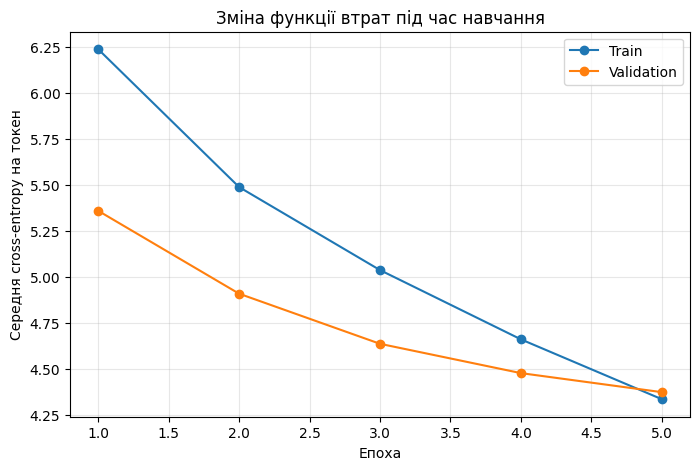

Інтерпретація: спад обох кривих означає, що модель навчається краще на обох наборах.
Якщо train loss падає, а validation loss зростає або відстає, це може свідчити про перенавчання.


In [7]:
epochs = range(1, EPOCHS + 1)
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train"], marker="o", label="Train")
plt.plot(epochs, history["validation"], marker="o", label="Validation")
plt.xlabel("Епоха")
plt.ylabel("Середня cross-entropy на токен")
plt.title("Зміна функції втрат під час навчання")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

print("Інтерпретація: спад обох кривих означає, що модель навчається краще на обох наборах.")
print("Якщо train loss падає, а validation loss зростає або відстає, це може свідчити про перенавчання.")

## 5. Greedy-переклад та увага

Greedy decoding на кожному кроці вибирає токен із найбільшим logit; це не гарантує глобально найкращий переклад, але дає простий приклад роботи моделі. На heatmap рядок відповідає згенерованому німецькому токену, стовпець — вхідному англійському. Увагу слід трактувати як внутрішню вагу моделі, а не як доказ причинності чи гарантованого мовного вирівнювання.

In [8]:
@torch.no_grad()
def translate_tokens(source_tokens, max_length=MAX_TOKENS):
    model.eval()
    source_ids = [source_vocab.get(token, UNK_IDX) for token in source_tokens]
    source = torch.tensor(source_ids, dtype=torch.long, device=device).unsqueeze(0)
    lengths = torch.tensor([len(source_ids)])
    encoder_outputs, state = model.encoder(source, lengths)
    source_mask = source.ne(model.source_pad_idx)
    token = torch.tensor([model.target_bos_idx], device=device)
    generated, attention_rows = [], []

    for _ in range(max_length):
        logits, state, weights = model.decoder.forward_step(
            token, state, encoder_outputs, source_mask
        )
        token_id = logits.argmax(dim=1).item()
        if token_id == EOS_IDX:
            break
        generated.append(token_id)
        attention_rows.append(weights[0].cpu())
        token = torch.tensor([token_id], device=device)

    generated_tokens = [target_itos[index] for index in generated]
    attention = (
        torch.stack(attention_rows).numpy()
        if attention_rows else torch.empty((0, len(source_tokens))).numpy()
    )
    return generated_tokens, attention


def detokenize(tokens):
    # Відновлюємо читабельні пробіли для пунктуації без повної мовної моделі spaCy.
    text = " ".join(tokens)
    for punctuation in (".", ",", ";", ":", "!", "?", "%", ")", "]"):
        text = text.replace(" " + punctuation, punctuation)
    for punctuation in ("(", "["):
        text = text.replace(punctuation + " ", punctuation)
    return text


NUM_EXAMPLES = min(3, len(valid_examples))
for index in range(NUM_EXAMPLES):
    source_tokens, reference_tokens = valid_examples[index]
    predicted_tokens, _ = translate_tokens(source_tokens)
    print(f"EN:         {detokenize(source_tokens)}")
    print(f"DE модель:  {detokenize(predicted_tokens)}")
    print(f"DE еталон:  {detokenize(reference_tokens)}")
    print("-" * 80)

EN:         these are hard times and, like belgium, we are a small country.
DE модель:  diese sind und und,,, wir wir eine <unk> land.
DE еталон:  die zeiten sind schwer, und ebenso wie belgien sind wir ein kleines land.
--------------------------------------------------------------------------------
EN:         they are very often victims of religious or cultural traditions, and i believe we need to take stock of the concept of religious and cultural traditions used to oppress a quite specific group, namely girls and women in general.
DE модель:  sie sind, dass die <unk> oder oder,,,,, wir wir, die <unk> und <unk>, und <unk>, <unk> und <unk> <unk> und frauen und frauen.
DE еталон:  sie werden oft opfer religiöser oder kultureller traditionen und ich glaube, dass wir uns mit dem begriff religiöse und kulturelle traditionen auseinander setzen müssen, mit dessen hilfe eine bestimmte gruppe unterdrückt wird, nämlich mädchen und frauen im allgemeinen.
--------------------------------------

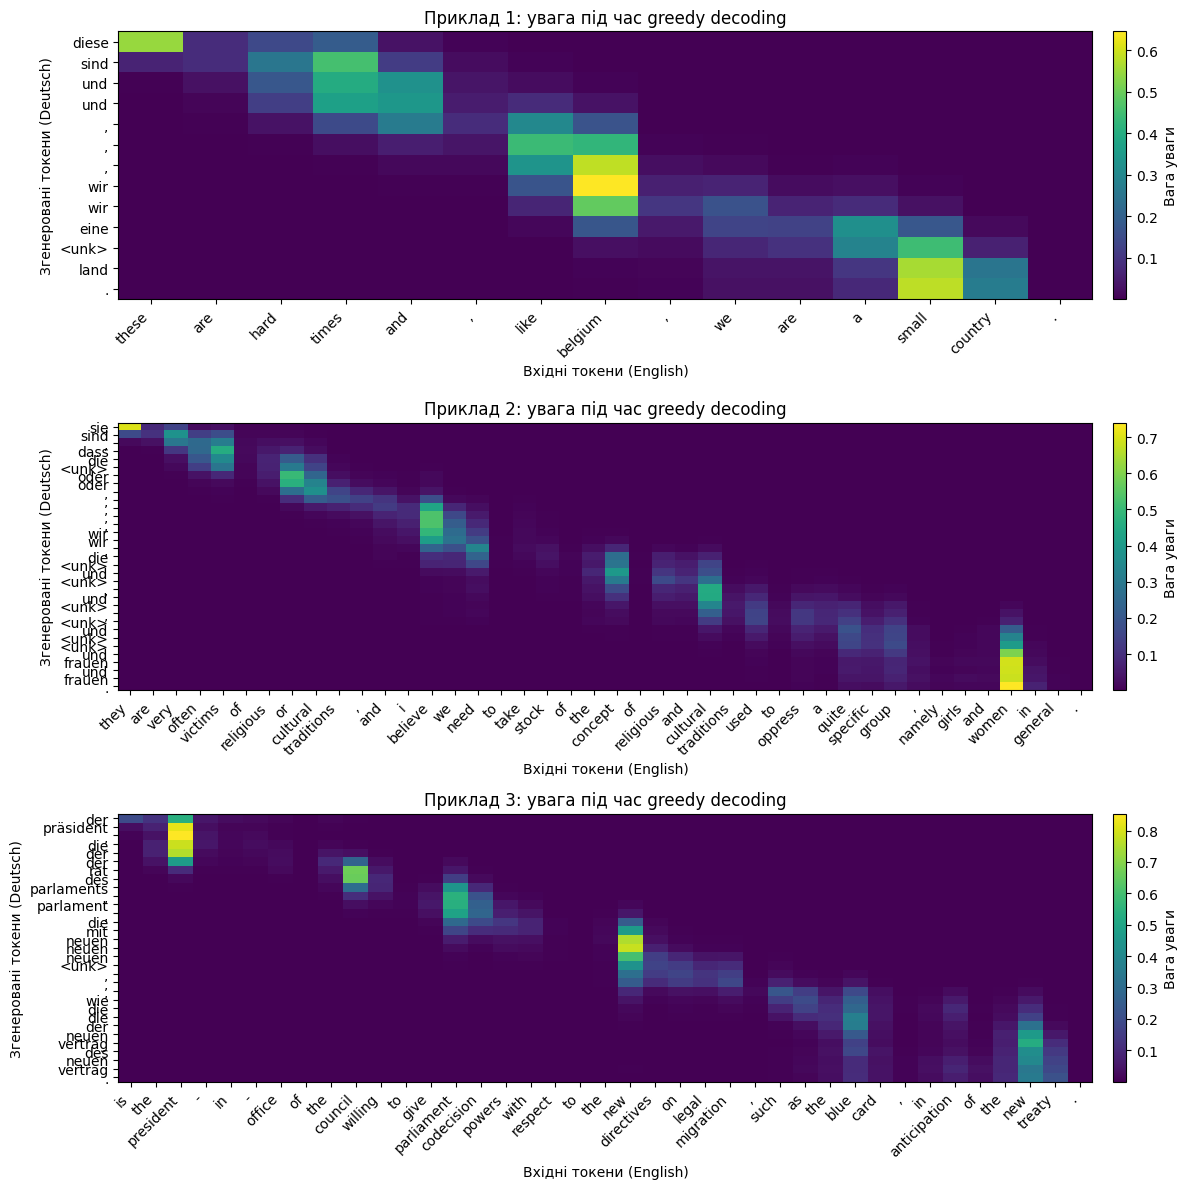

In [9]:
fig, axes = plt.subplots(NUM_EXAMPLES, 1, figsize=(12, 4 * NUM_EXAMPLES), squeeze=False)
for index, axis in enumerate(axes[:, 0]):
    source_tokens, reference_tokens = valid_examples[index]
    predicted_tokens, attention = translate_tokens(source_tokens)
    if len(predicted_tokens) == 0:
        axis.set_title("Модель згенерувала EOS без текстових токенів")
        axis.axis("off")
        continue

    image = axis.imshow(attention, aspect="auto", cmap="viridis")
    axis.set_xticks(range(len(source_tokens)))
    axis.set_xticklabels(source_tokens, rotation=45, ha="right")
    axis.set_yticks(range(len(predicted_tokens)))
    axis.set_yticklabels(predicted_tokens)
    axis.set_xlabel("Вхідні токени (English)")
    axis.set_ylabel("Згенеровані токени (Deutsch)")
    axis.set_title(f"Приклад {index + 1}: увага під час greedy decoding")
    fig.colorbar(image, ax=axis, fraction=0.025, pad=0.02, label="Вага уваги")

fig.tight_layout()
plt.show()

## 6. Аналіз і висновки

Результати та висновки. Для експерименту було завантажено корпус Europarl для мовної пари німецька–англійська, а напрямок перекладу налаштовано як англійська → німецька. Із початкових 20 000 випадково вибраних пар після фільтрації залишилося 18 043: 16 238 навчальних і 1 805 валідаційних прикладів. Розмір словника становив 8 523 токени для англійської та 12 174 для німецької.

Модель — Seq2Seq із двонапрямним GRU-енкодером, GRU-декодером і адитивною увагою Bahdanau — навчалася п’ять епох на GPU (cuda). Train loss зменшився з 6.2353 до 4.3345, а validation loss — з 5.3577 до 4.3728. Обидві криві спадали; наприкінці їхні значення були близькими, тож за цим коротким запуском немає явної ознаки сильного перенавчання.

Водночас ці метрики не цілком зіставні: під час тренування використовувався teacher forcing 0.5, а під час валідації — 1.0. Отже, близькість кінцевих значень є корисним спостереженням, але не строгим порівнянням однакових умов.

Приклади перекладу показали, що модель поки генерує неточний текст із повтореннями та <unk>; довгі речення особливо складні. На теплових картах уваги видно, що в деяких місцях ваги зосереджені на окремих вхідних словах або фрагментах, але вирівнювання непослідовне. Увага допомагає побачити, на які позиції джерела модель спиралася, однак сама по собі не гарантує правильного перекладу.

Загалом, loss зменшується, але п’яти епох і підмножини даних недостатньо для якісних перекладів. Для покращення можна збільшити кількість епох і навчальних даних, переглянути обробку невідомих слів або використати subword-токенізацію.